## Energy consumption in Brussels

Sibelga regularly publishes the yearly consumption for the different municipalities in the Brussels region. Looking at the residential data, we can see that the average yearly consumption per household is around 2000 kWh, with some geographical differences: 

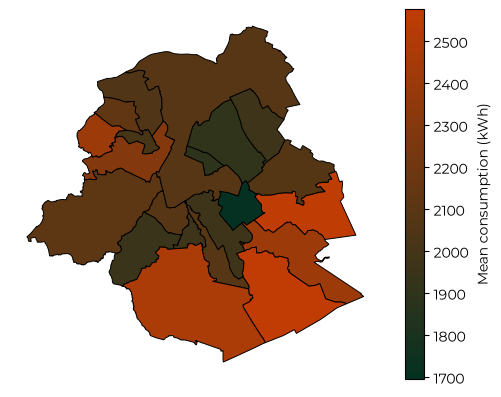

In [1]:
from pathlib import Path
import pandas as pd
import geopandas as gpd
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import font_manager as fm

for f in Path("fonts").glob("*.ttf"):   # path relative to the notebook
    fm.fontManager.addfont(str(f))
plt.rcParams["font.family"] = "Montserrat"

from matplotlib.colors import LinearSegmentedColormap
cmap = LinearSegmentedColormap.from_list("swifft_map", ["#043122", "#C03C04"])

df_consumption = pd.read_csv("../data/202312-yearly-consumption-elec-2023.csv", sep=";", decimal=".")
df_consumption_res = df_consumption[df_consumption['CUSTOMER_TYPE_FR_TX'] == 'RES']
df_consumption_res['CITY_FR_TX'] = df_consumption_res['CITY_FR_TX'].replace(r"Brux.*", "Bruxelles", regex=True)
df_consumption_res['AVERAGE_KWH'] = df_consumption_res['VOLUME_KWH'] / df_consumption_res['COUNT_EAN']
df_mean_cons = df_consumption_res.groupby('CITY_FR_TX')['AVERAGE_KWH'].mean().sort_values(ascending=False)

# Load a polygon layer containing the Brussels municipalities.
municipalities = gpd.read_file("../data/limites-administratives-des-communes-en-region-de-bruxelles-capitale.geojson")
results = df_mean_cons.rename("mean_kwh").rename_axis("CITY_FR_TX").reset_index()
map_data = municipalities.merge(results, left_on="name_fr", right_on="CITY_FR_TX", how="left")

ax = map_data.plot(column="mean_kwh", cmap=cmap, legend=True, edgecolor="black", linewidth=0.7, missing_kwds={"color": "lightgrey", "label": "No data"}, legend_kwds={"label": "Mean consumption (kWh)"})
ax.set_axis_off()
fig = ax.get_figure()
plt.show()

The municipalities consuming a larger share of energy are the ones on the south: Woluwe-Saint-Pierre, Auderghem, Watermael-Boitsfort, Uccle, which also happen to be the richest municipalities. 
This is supported by looking at the average income data. The IBSA (Institut Bruxellois de Statistique et d'Analyse) publishes the equivalent average income per inhabitant after taxes, which we can compare with the average consumption.

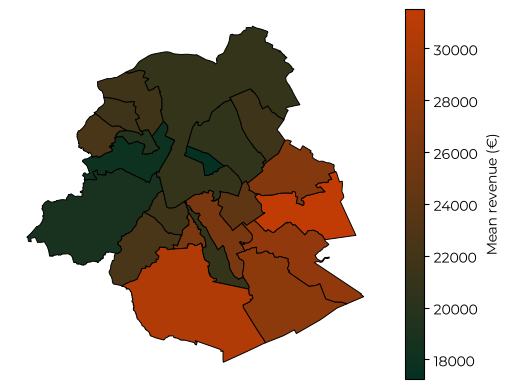

In [2]:
df_revenues = pd.read_excel("../data/2.1b_rev_dep_menages_stat_fisc_menages_prives_20260526.xlsx", sheet_name="2.1.5.7", skiprows=3, engine="calamine")
df_revenues = df_revenues.rename(columns={"Unnamed: 0": "CITY_FR_TX"})
df_revenues_2023 = df_revenues[["CITY_FR_TX", 2023]].rename(columns={2023: "AVG_REVENUE"})

df_joint = pd.merge(df_mean_cons, df_revenues_2023, on="CITY_FR_TX", how="left")
# print(df_joint)
map_data_revenues = municipalities.merge(df_joint, left_on="name_fr", right_on="CITY_FR_TX", how="left")
ax = map_data_revenues.plot(column="AVG_REVENUE", cmap=cmap, legend=True, edgecolor="black", linewidth=0.7, missing_kwds={"color": "lightgrey", "label": "No data"}, legend_kwds={"label": "Mean revenue (€)"})
ax.set_axis_off()
fig = ax.get_figure()
plt.show()



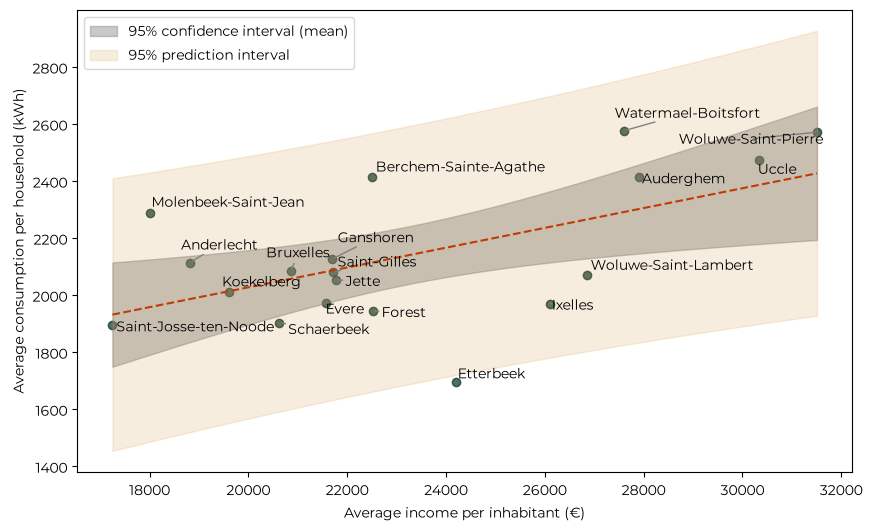

                            OLS Regression Results                            
Dep. Variable:            AVERAGE_KWH   R-squared:                       0.328
Model:                            OLS   Adj. R-squared:                  0.288
Method:                 Least Squares   F-statistic:                     8.297
Date:                Fri, 06 Nov 2026   Prob (F-statistic):             0.0104
Time:                        10:40:01   Log-Likelihood:                -127.43
No. Observations:                  19   AIC:                             258.9
Df Residuals:                      17   BIC:                             260.7
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                  coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------
const        1331.6064    284.313      4.684      

In [21]:
import numpy as np
from adjustText import adjust_text
import statsmodels.api as sm

X = sm.add_constant(df_joint["AVG_REVENUE"])
model = sm.OLS(df_joint["AVERAGE_KWH"], X).fit()
intercept = model.params['const']
slope = model.params['AVG_REVENUE']

n_pred = 100
input_values = np.ones((n_pred, 2))
input_values[:, 1] = np.linspace(df_joint["AVG_REVENUE"].min(), df_joint["AVG_REVENUE"].max(), n_pred)
prediction = model.get_prediction(input_values)
frame = prediction.summary_frame(alpha=0.05)

fig, ax = plt.subplots(figsize=(10, 6))
ax.scatter(df_joint["AVG_REVENUE"], df_joint["AVERAGE_KWH"], color='#043122', alpha=0.7)
ax.plot(input_values[:, 1], frame['mean'], color="#C03C04", ls='--')
ax.fill_between(input_values[:, 1], frame["mean_ci_lower"], frame["mean_ci_upper"], alpha=0.4, label="95% confidence interval (mean)", color="#7A7A7A")
ax.fill_between(input_values[:, 1], frame["obs_ci_lower"], frame["obs_ci_upper"], alpha=0.15, label="95% prediction interval", color="#CF8B25")
ax.set_xlabel("Average income per inhabitant (€)")
ax.set_ylabel("Average consumption per household (kWh)")
ax.legend()

texts = [ax.text(xi, yi, l) for xi, yi, l in zip(df_joint["AVG_REVENUE"], df_joint["AVERAGE_KWH"], df_joint["CITY_FR_TX"])]
adjust_text(texts, arrowprops=dict(arrowstyle="-", color="gray"))

plt.show()

print(model.summary())


The data shows a clear correlation between income and energy consumption, with a confidence greater than 95%, even if the average income explains only around 25% of the variance in the consumption, meaning that there are other factors that contributes to increase or decrease the energy consumption, of course. 

However, there are some outliers like Etterbeek who consumes less than what would be predicted given its average income, and Molenbeek which consumes more. An issue with this dataset is that the consumption is given per household while the income is per inhabitant. A possible explanation is that Etterbeek has a smaller number of inhabiotants per household on average, which would explain the lower consumption per household.

To check this hypothesis, I have computed the average size of households for the different municipalities, and I have computed the average income per household as the average income per inhabitants multiplied by the average size of the households.


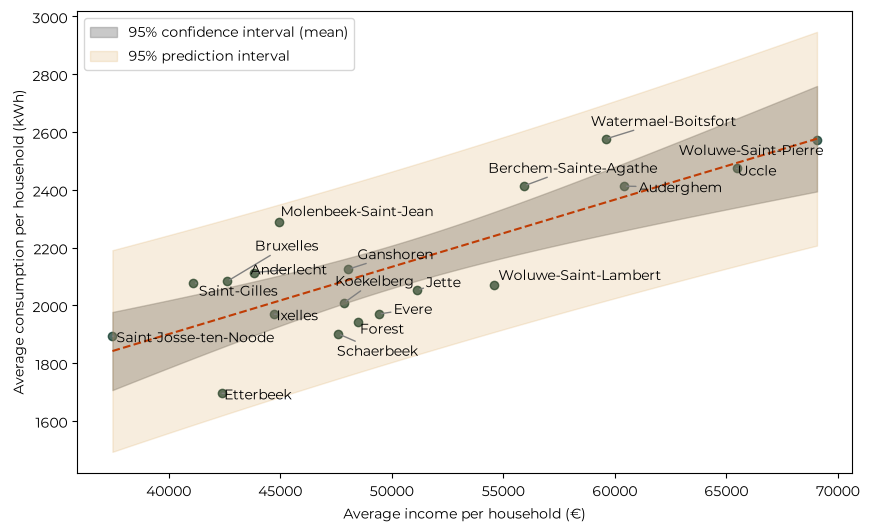

                            OLS Regression Results                            
Dep. Variable:            AVERAGE_KWH   R-squared:                       0.643
Model:                            OLS   Adj. R-squared:                  0.622
Method:                 Least Squares   F-statistic:                     30.63
Date:                Fri, 06 Nov 2026   Prob (F-statistic):           3.64e-05
Time:                        10:45:51   Log-Likelihood:                -121.42
No. Observations:                  19   AIC:                             246.8
Df Residuals:                      17   BIC:                             248.7
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                                coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------------------
const                 

In [22]:
df_households = pd.read_excel("../data/1.4_population_menages_20260826.xlsx", sheet_name="1.4.1.1", skiprows=3, engine="calamine")
df_households = df_households.rename(columns={"Unnamed: 0": "CITY_FR_TX"})
df_households_2023 = df_households[["CITY_FR_TX", 2023]].rename(columns={2023: "N_HOUSEHOLDS"})

df_citizens = pd.read_excel("../data/1.4_population_menages_20260826.xlsx", sheet_name="1.4.1.2", skiprows=3, engine="calamine")
df_citizens = df_citizens.rename(columns={"Unnamed: 0": "CITY_FR_TX"})
df_citizens_2023 = df_citizens[["CITY_FR_TX", 2023]].rename(columns={2023: "N_CITIZENS"})

df_households_2023['N_CITIZENS'] = df_citizens_2023['N_CITIZENS']
df_households_2023['AVG_HOUSEHOLD_SIZE'] = df_households_2023['N_CITIZENS'] / df_households_2023['N_HOUSEHOLDS']

df_joint_total = pd.merge(df_joint, df_households_2023, on="CITY_FR_TX", how="left")
df_joint_total['AVG_REVENUE_PER_HOUSEHOLD'] = df_joint_total['AVG_REVENUE'] * df_joint_total['AVG_HOUSEHOLD_SIZE']

X = sm.add_constant(df_joint_total["AVG_REVENUE_PER_HOUSEHOLD"])
model = sm.OLS(df_joint_total["AVERAGE_KWH"], X).fit()
intercept = model.params['const']
slope = model.params['AVG_REVENUE_PER_HOUSEHOLD']

n_pred = 100
input_values = np.ones((n_pred, 2))
input_values[:, 1] = np.linspace(df_joint_total["AVG_REVENUE_PER_HOUSEHOLD"].min(), df_joint_total["AVG_REVENUE_PER_HOUSEHOLD"].max(), n_pred)
prediction = model.get_prediction(input_values)
frame = prediction.summary_frame(alpha=0.05)

fig, ax = plt.subplots(figsize=(10, 6))
ax.scatter(df_joint_total["AVG_REVENUE_PER_HOUSEHOLD"], df_joint_total["AVERAGE_KWH"], color='#043122', alpha=0.7)
ax.plot(input_values[:, 1], frame['mean'], color="#C03C04", ls='--')
ax.fill_between(input_values[:, 1], frame["mean_ci_lower"], frame["mean_ci_upper"], alpha=0.4, label="95% confidence interval (mean)", color="#7A7A7A")
ax.fill_between(input_values[:, 1], frame["obs_ci_lower"], frame["obs_ci_upper"], alpha=0.15, label="95% prediction interval", color="#CF8B25")
ax.legend()

ax.set_xlabel("Average income per household (€)") 
ax.set_ylabel("Average consumption per household (kWh)")

texts = [ax.text(xi, yi, l) for xi, yi, l in zip(df_joint_total["AVG_REVENUE_PER_HOUSEHOLD"], df_joint_total["AVERAGE_KWH"], df_joint_total["CITY_FR_TX"])]
adjust_text(texts, arrowprops=dict(arrowstyle="-", color="gray"))

plt.show()

print(model.summary())


Now the correlation signal is stronger than before, with a r-squared of 0.64, meaning that the average household income alone explains 64% of the variance in the consumption.

From one point of view, this correlation is understandable considering that more purchasing power equates to bigger homes and thus higher consumption. However, from another point of view, a bigger revenue should allow for better houses which are more insulated, with more efficient energy systems. Evidently, the first mechanism is more powerful than the second one.

On a small scale, this replicates exactly the global [phenomenon](https://energyforgrowth.org/article/high-income-low-energy-countries-dont-exist-update-sep-2024/) in which higher income per capita aligns very well with higher electricity consumption.